In [13]:
import os
import numpy as np
from ase.db import connect
from tqdm import tqdm
import glob
from collections import defaultdict
import random
import matplotlib.pyplot as plt

In [2]:
data_dir = os.path.expanduser("~/Desktop/train_4M")

shards = sorted([
    os.path.join(data_dir, f)
    for f in os.listdir(data_dir)
    if f.endswith(".aselmdb")
])

save_dir = os.path.join(data_dir, "phase_space_features")
os.makedirs(save_dir, exist_ok=True)

print(f"Found {len(shards)} shards")

Found 80 shards


In [3]:
for i, shard_path in enumerate(tqdm(shards, desc="Shards")):
    
    db = connect(shard_path)
    
    features = []
    
    for row in tqdm(db.select(), total=len(db), leave=False):
        atoms = row.toatoms()
        Z = atoms.get_atomic_numbers()
        
        N = len(Z)
        Z = np.array(Z)
        
        if N > 1:
            top2 = np.partition(Z, -2)[-2:]
            max_pair_weight = int(top2[0] * top2[1])
            Z_max = int(top2.max())
        else:
            max_pair_weight = 0
            Z_max = int(Z[0])
        
        Z_sum = int(Z.sum())
        
        features.append([N, max_pair_weight, Z_max, Z_sum])
    
    features = np.array(features, dtype=np.int32)
    
    # save per shard
    save_path = os.path.join(save_dir, f"phase_space_{i:04d}.npy")
    np.save(save_path, features)

print("Done processing all shards.")

Shards: 100%|██████████| 80/80 [51:55<00:00, 38.95s/it]

Done processing all shards.


In [4]:
files = sorted(glob.glob(os.path.join(save_dir, "*.npy")))

all_features = []
for f in tqdm(files, desc="Merging"):
    all_features.append(np.load(f))

all_features = np.vstack(all_features)

np.save(os.path.join(save_dir, "phase_space_all.npy"), all_features)

print("Final shape:", all_features.shape)

Merging: 100%|██████████| 80/80 [00:00<00:00, 601.12it/s]


Final shape: (3986754, 4)


In [5]:
# assuming all_features = [N, pair_weight, Zmax, Zsum]

N_atoms = all_features[:, 0]
pair_weight = all_features[:, 1]

# ---- define bins ----

# avoid log(0)
pair_weight_safe = np.clip(pair_weight, 1, None)

# log bins for pair weight
x_bins = np.logspace(
    np.log10(pair_weight_safe.min()),
    np.log10(pair_weight_safe.max()),
    30
)

# linear bins for N_atoms
y_bins = np.linspace(
    N_atoms.min(),
    N_atoms.max(),
    30
)

In [6]:
x_idx = np.digitize(pair_weight_safe, x_bins)
y_idx = np.digitize(N_atoms, y_bins)

# combine into 2D bin ID
bin_ids = x_idx * 1000 + y_idx   # simple encoding trick

In [7]:
bin_dict = defaultdict(list)

for i, b in enumerate(bin_ids):
    bin_dict[b].append(i)

In [8]:
samples_per_bin = 50   # tune this

selected_indices = []

for b, indices in bin_dict.items():
    if len(indices) <= samples_per_bin:
        selected_indices.extend(indices)
    else:
        selected_indices.extend(
            random.sample(indices, samples_per_bin)
        )

In [9]:
sampled_features = all_features[selected_indices]

print("Sampled size:", len(sampled_features))

Sampled size: 20477


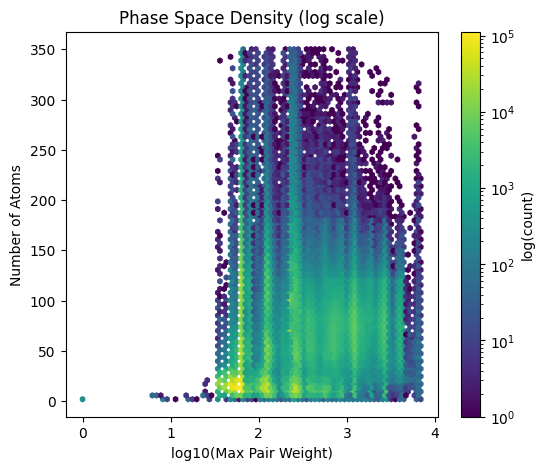

In [20]:
pair_weight = all_features[:, 1]
N_atoms = all_features[:, 0]

pair_weight_safe = np.clip(pair_weight, 1, None)

plt.figure(figsize=(6, 5))

plt.hexbin(
    np.log10(pair_weight_safe),
    N_atoms,
    gridsize=80,
    bins='log',
    cmap='viridis'
)

plt.xlabel("log10(Max Pair Weight)")
plt.ylabel("Number of Atoms")
plt.title("Phase Space Density (log scale)")

plt.colorbar(label="log(count)")
plt.show()